# SOM diagnostics for the XGBoost classifier

Each figure below contains one map only. Empty SOM cells are shown in white. The SOM was trained on the same scaled classifier features used by the classifier, so the diagnostic maps use the classifier test split and the exact BMU assignments from that SOM.

In [1]:
from joblib import load
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from kids.catalog.training_catalog import load_and_prepare_training_catalog, merge_training_catalogs
from kids.features import clf_features
from kids.ml.classifiers import XGBClf
from kids.ml.som import MySOM
from kids.training_data import TrainingData

In [2]:
kids_x_desi = load_and_prepare_training_catalog('../data/KiDS_DR5_WCScut_x_DESI_DR1_columns.csv')
kids_x_sdss = load_and_prepare_training_catalog('../data/KiDS_DR5_WCScut_x_SDSS_DR17_columns.csv')
catalog = merge_training_catalogs(kids_x_desi, kids_x_sdss)
training_data = TrainingData(catalog, clf_features)
X_test, y_test = training_data.get_test_clf()
y_test = np.asarray(y_test, dtype=int)
raw_test = training_data.data.loc[training_data.idx_test].reset_index(drop=True)
assert len(raw_test) == len(X_test) == len(y_test)

In [3]:
SOM_PATH = '../saved_models/som/test_som_60_60.pth'
XGB_PATH = '../saved_models/classification/xgb_clf_2026-10-20T20-10-35Z.json'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SOM_CONFIG = {
    'x': 60, 'y': 60, 'num_features': len(clf_features), 'epochs': 35,
    'batch_size': 4 * 1024, 'learning_rate': 0.8, 'sigma': 35,
    'device': DEVICE, 'topology': 'rectangular', 'pbc': True,
    'lr_decay_function': 'asymptotic_decay',
    'sigma_decay_function': 'lr_linear_decay_to_zero',
    'neighborhood_function': 'gaussian', 'distance_function': 'euclidean',
    'initialization_mode': 'pca',
}
preprocessor = load('../saved_models/som/preprocessor.joblib')
som = MySOM(**SOM_CONFIG)
som.load_state_dict(torch.load(SOM_PATH, map_location=DEVICE, weights_only=True))
som.eval()
xgb_clf = XGBClf()
xgb_clf.load(XGB_PATH)
assert tuple(som.weights.shape) == (SOM_CONFIG['x'], SOM_CONFIG['y'], len(clf_features))

In [4]:
X_som = preprocessor.transform(raw_test.loc[:, clf_features])
with torch.no_grad():
    X_tensor = torch.as_tensor(X_som, dtype=torch.float32, device=DEVICE)
    bmus = som.identify_bmus(X_tensor).cpu().numpy()
    bmu_weights = som.weights[bmus[:, 0], bmus[:, 1]]
    bmu_distance = torch.linalg.vector_norm(X_tensor - bmu_weights, dim=1).cpu().numpy()
probabilities = np.asarray(xgb_clf.model.predict_proba(X_test))
predicted = probabilities.argmax(axis=1)
confidence = probabilities.max(axis=1)
assert probabilities.shape == (len(y_test), len(TrainingData.CLASS_TO_ID))
assert np.isclose(probabilities.sum(axis=1), 1).all()
assert np.array_equal(predicted, np.asarray(xgb_clf.predict(X_test), dtype=int))

In [5]:
n_x, n_y = SOM_CONFIG['x'], SOM_CONFIG['y']
cell_id = bmus[:, 0] * n_y + bmus[:, 1]
classes = list(TrainingData.CLASS_TO_ID)
assignments = pd.DataFrame({
    'cell_id': cell_id, 'bmu_x': bmus[:, 0], 'bmu_y': bmus[:, 1],
    'bmu_distance': bmu_distance, 'true_class_id': y_test,
    'predicted_class_id': predicted, 'confidence': confidence,
    'correct': predicted == y_test,})
cell_stats = assignments.groupby('cell_id').agg(
    count=('correct', 'size'),
    error_rate=('correct', lambda values: 1 - values.mean()),
    mean_confidence=('confidence', 'mean'),
    accuracy=('correct', 'mean'),
    mean_bmu_distance=('bmu_distance', 'mean'),
    bmu_x=('bmu_x', 'first'), bmu_y=('bmu_y', 'first'))
cell_stats['calibration_gap'] = cell_stats['mean_confidence'] - cell_stats['accuracy']
true_counts = pd.crosstab(assignments['cell_id'], assignments['true_class_id'])
true_counts = true_counts.reindex(index=cell_stats.index, columns=range(len(classes)), fill_value=0)
true_fractions = true_counts.div(cell_stats['count'], axis=0)
for class_id, class_name in TrainingData.ID_TO_CLASS.items():
    class_key = class_name.lower()
    cell_stats[f'true_fraction_{class_key}'] = true_fractions[class_id]

cell_stats['class_purity'] = true_fractions.max(axis=1)
cell_stats['class_entropy'] = -(true_fractions * np.log(true_fractions.replace(0, np.nan))).sum(axis=1)
for class_id, class_name in TrainingData.ID_TO_CLASS.items():
    class_key = class_name.lower()
    true_positive = ((assignments['true_class_id'] == class_id) &
                     (assignments['predicted_class_id'] == class_id)).groupby(assignments['cell_id']).sum()
    predicted_count = (assignments['predicted_class_id'] == class_id).groupby(assignments['cell_id']).sum()
    actual_count = (assignments['true_class_id'] == class_id).groupby(assignments['cell_id']).sum()
    cell_stats[f'precision_{class_key}'] = true_positive / predicted_count.replace(0, np.nan)
    cell_stats[f'recall_{class_key}'] = true_positive / actual_count.replace(0, np.nan)

assert cell_stats['count'].sum() == len(assignments)
assert np.allclose(true_fractions.sum(axis=1), 1)


In [6]:
from pathlib import Path
import re

FIG_DIR = Path('../figs')
FIG_DIR.mkdir(parents=True, exist_ok=True)


def _figure_path(title):
    slug = re.sub(r'[^a-z0-9]+', '_', title.lower()).strip('_')
    return FIG_DIR / f'{slug}.png'


def plot_cell_map(values, title, *, cmap='viridis', vmin=None, vmax=None, center=None):
    values = np.asarray(values)
    if values.shape == (n_x, n_y):
        grid = values.copy()
    else:
        if values.size != len(cell_stats):
            raise ValueError(
                f'Expected one value per occupied cell ({len(cell_stats)}) '
                f'or a full SOM grid ({n_x}, {n_y}); got {values.shape}.'
            )
        grid = np.full((n_x, n_y), np.nan)
        grid[cell_stats['bmu_x'].to_numpy(dtype=int), cell_stats['bmu_y'].to_numpy(dtype=int)] = values
    fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)
    if center is not None:
        limit = max(abs(np.nanmin(grid - center)), abs(np.nanmax(grid - center)))
        vmin, vmax = center - limit, center + limit
    image = ax.imshow(grid.T, origin='lower', interpolation='nearest', cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set(title=title, xlabel='SOM x', ylabel='SOM y')
    fig.colorbar(image, ax=ax, label=title)
    fig.savefig(_figure_path(title), dpi=150)
    plt.show()


def plot_som_component(feature_name):
    if feature_name not in clf_features:
        raise ValueError(f'{feature_name!r} is not a feature in the saved SOM.')
    plot_cell_map(som.weights[:, :, clf_features.index(feature_name)].cpu().numpy(),
                  f'SOM component plane: {feature_name}', cmap='coolwarm')


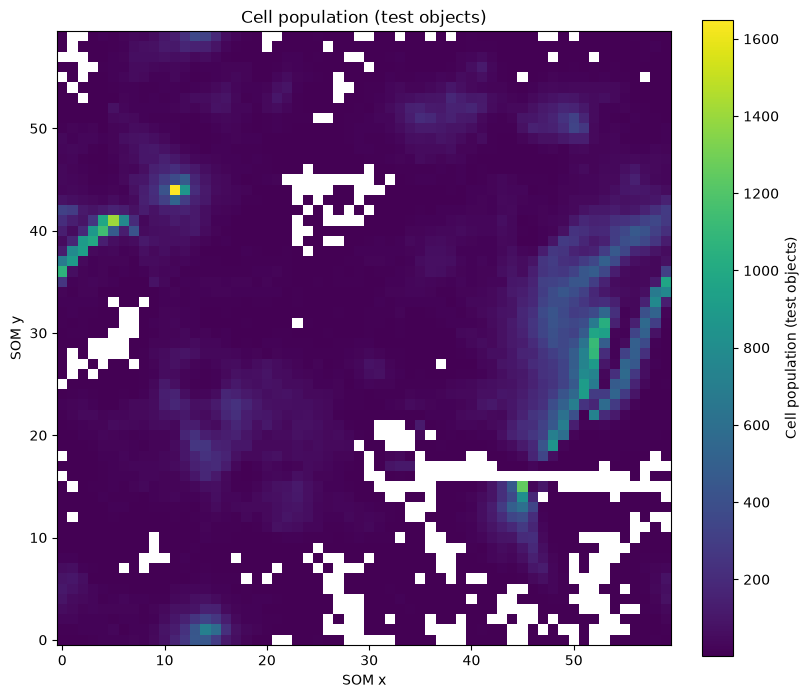

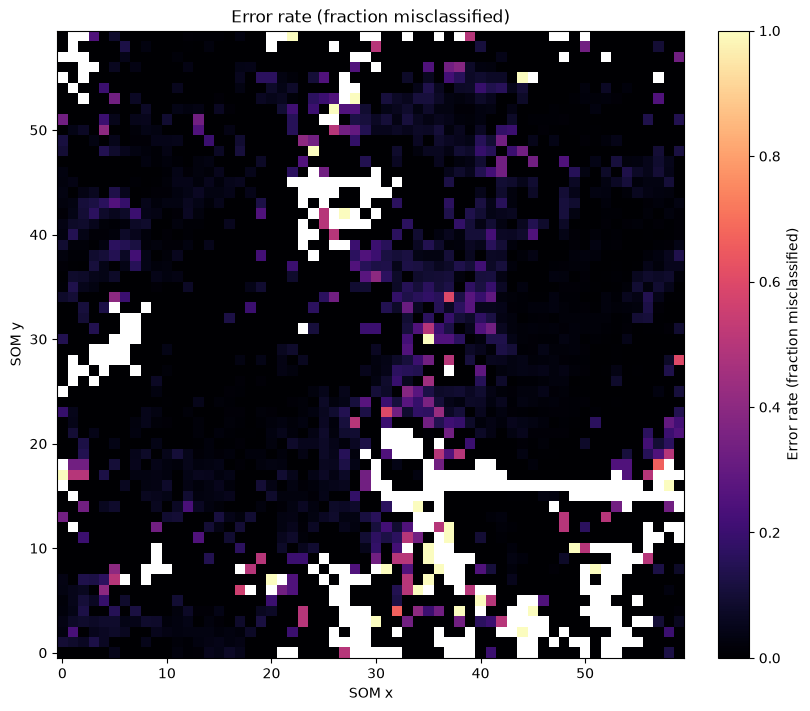

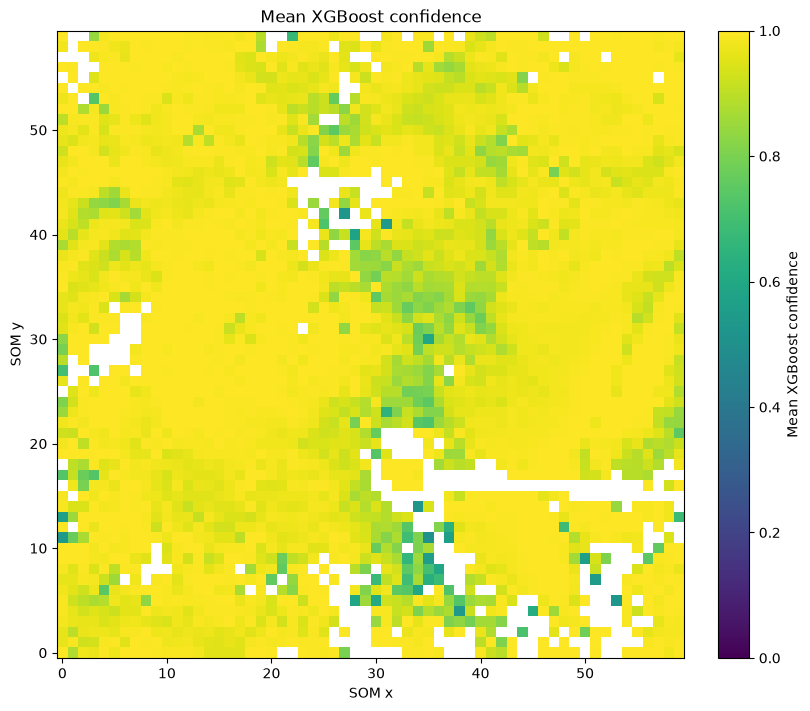

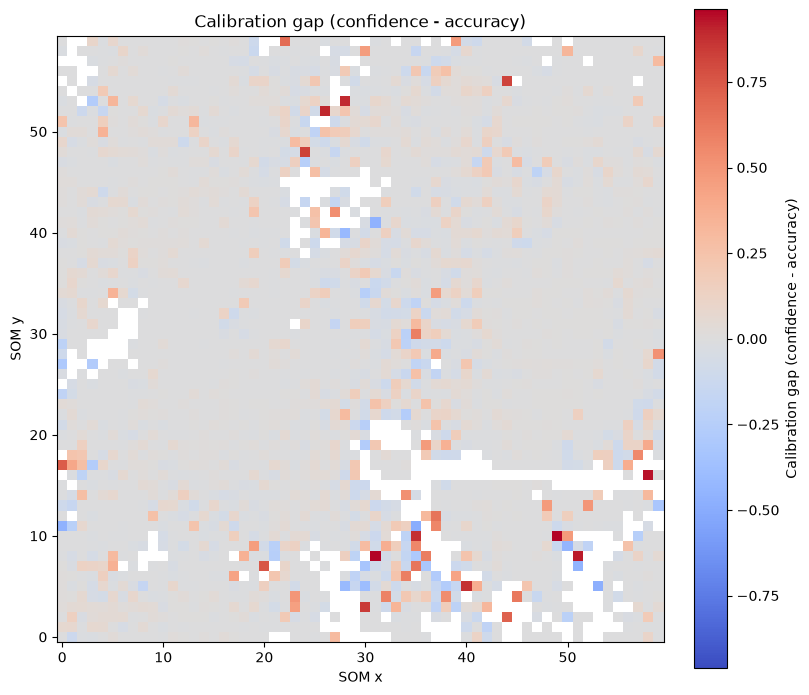

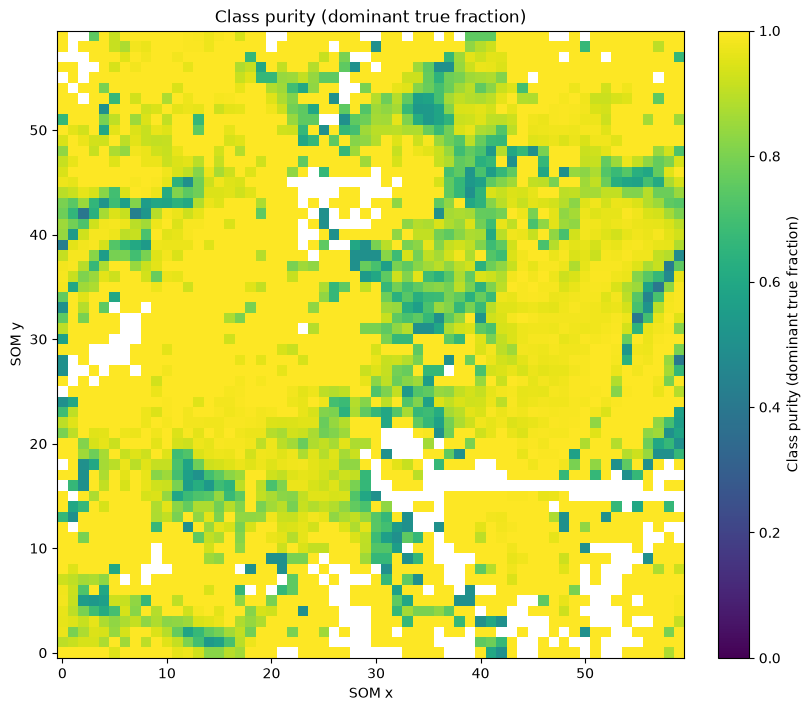

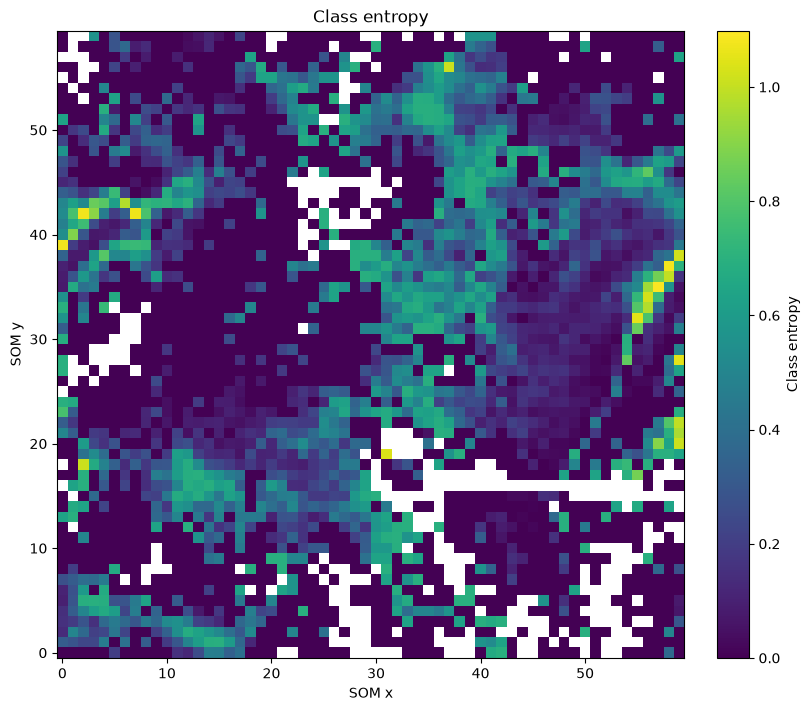

In [7]:
plot_cell_map(cell_stats['count'], 'Cell population (test objects)', cmap='viridis')
plot_cell_map(cell_stats['error_rate'], 'Error rate (fraction misclassified)', vmin=0, vmax=1, cmap='magma')
plot_cell_map(cell_stats['mean_confidence'], 'Mean XGBoost confidence', vmin=0, vmax=1)
plot_cell_map(cell_stats['calibration_gap'], 'Calibration gap (confidence - accuracy)', center=0, cmap='coolwarm')
plot_cell_map(cell_stats['class_purity'], 'Class purity (dominant true fraction)', vmin=0, vmax=1)
plot_cell_map(cell_stats['class_entropy'], 'Class entropy', vmin=0, vmax=np.log(len(classes)))


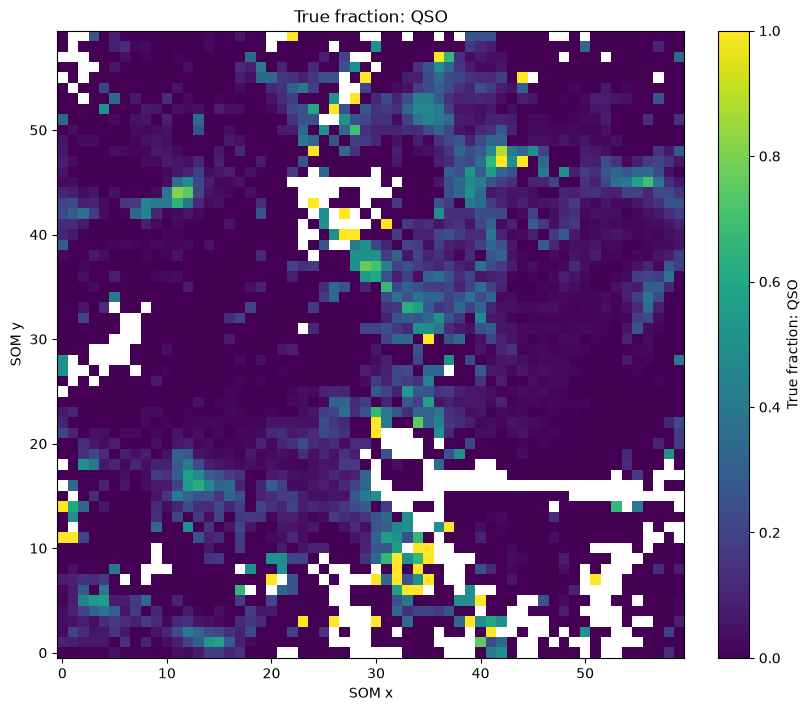

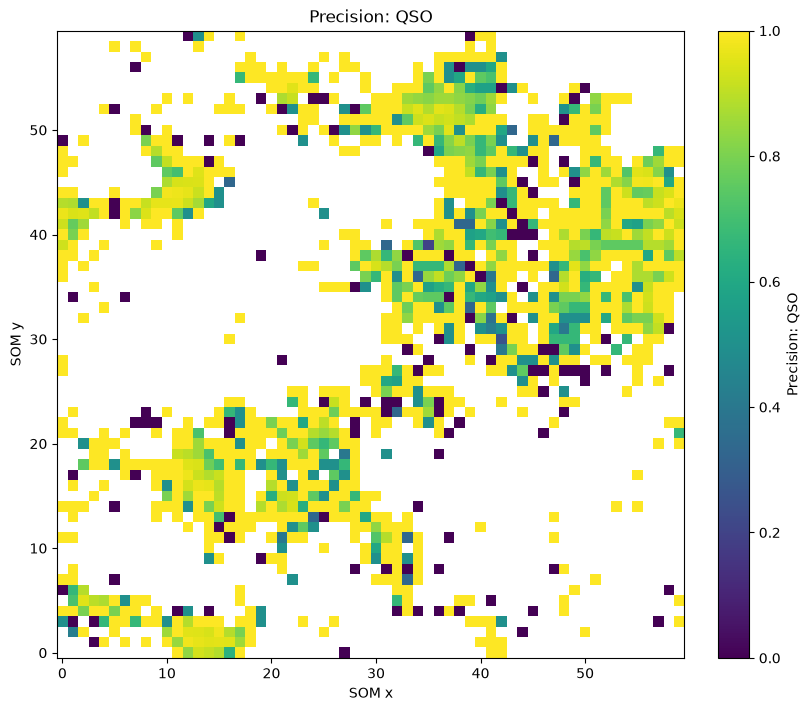

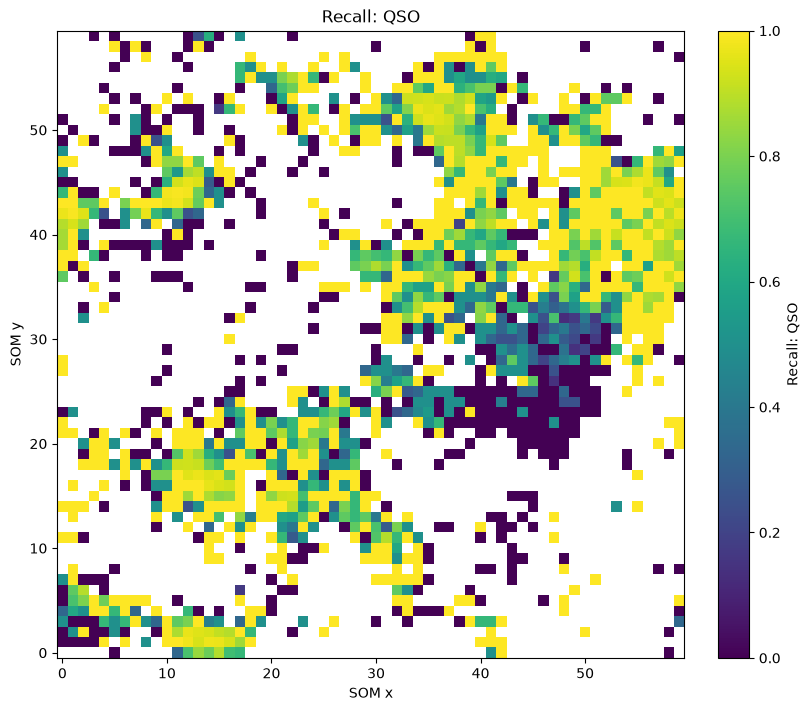

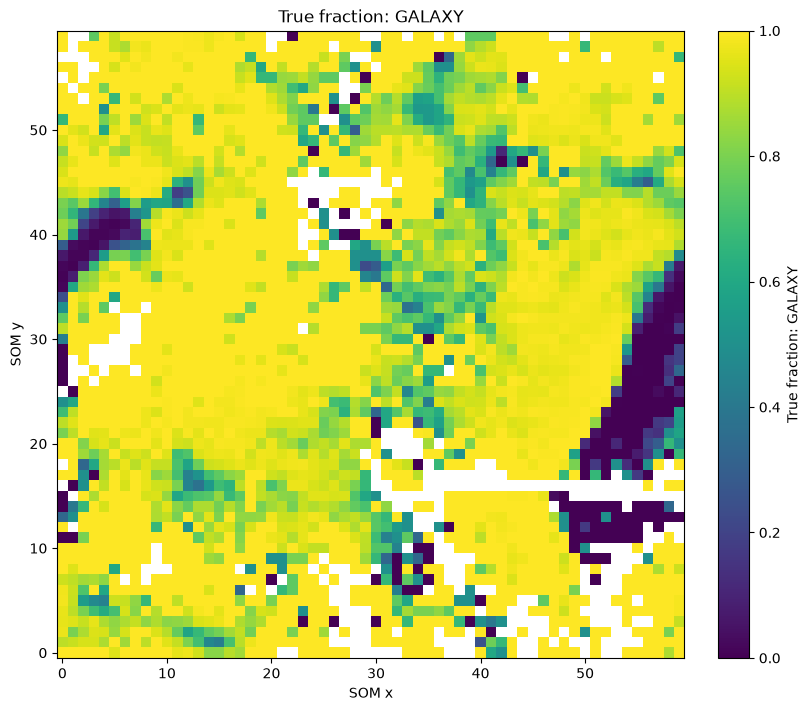

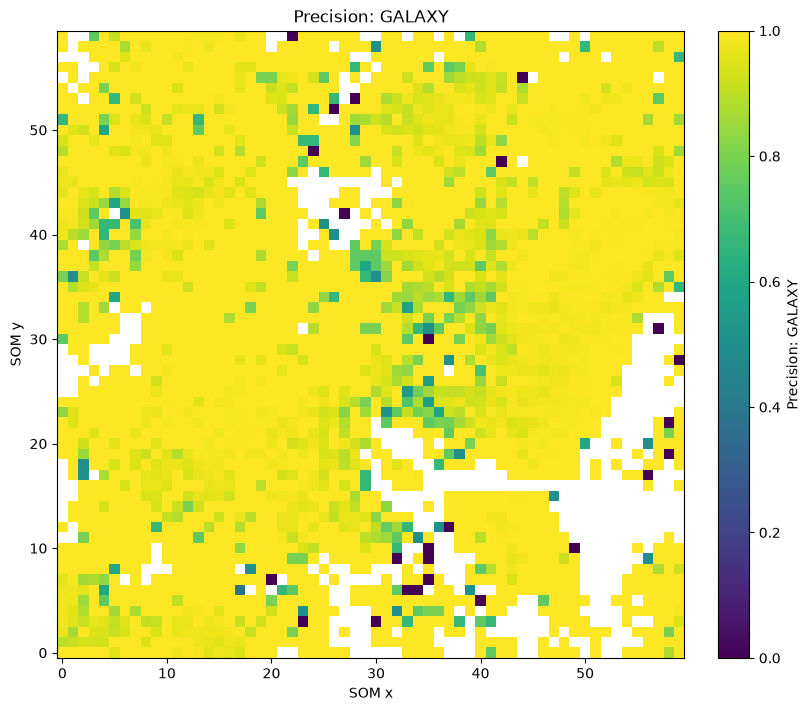

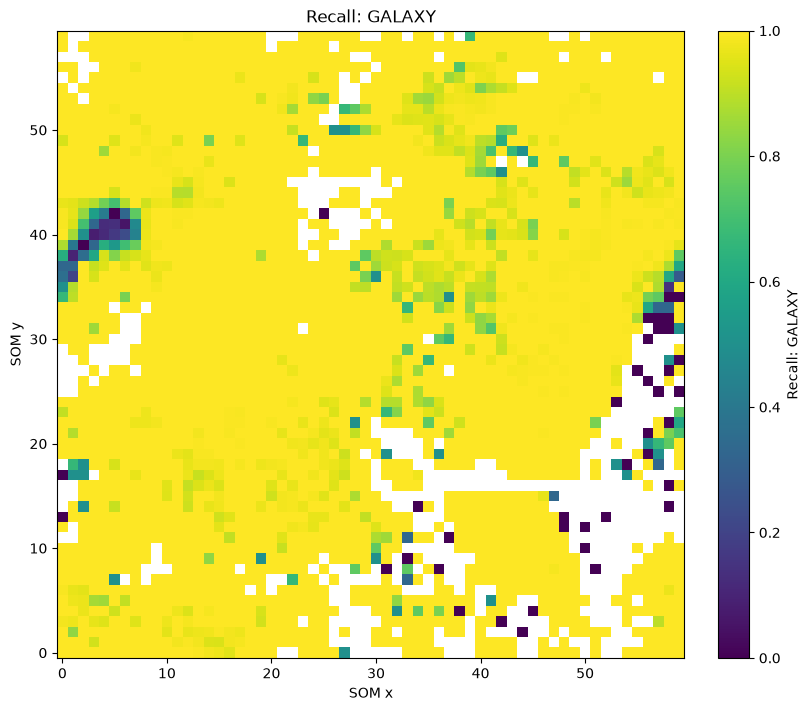

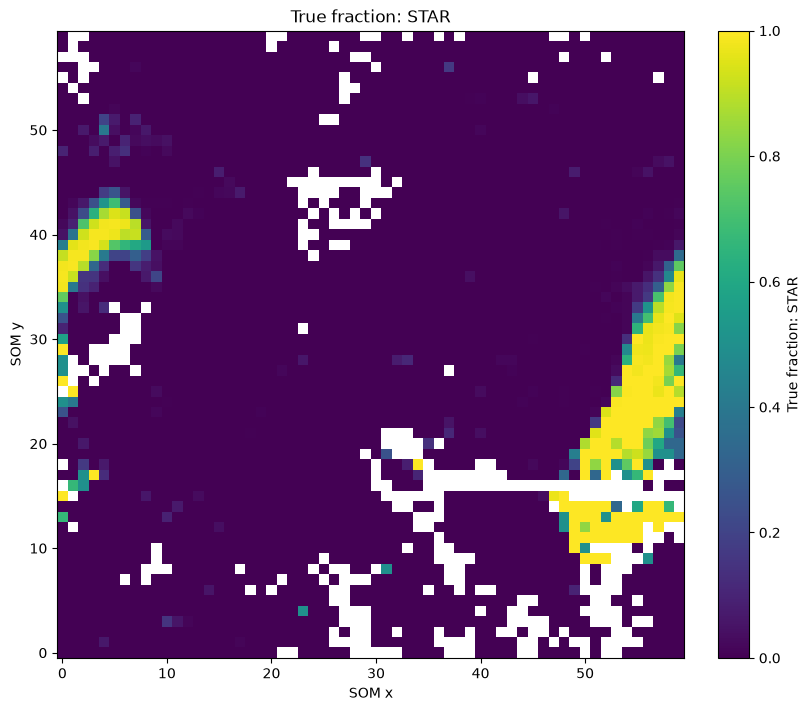

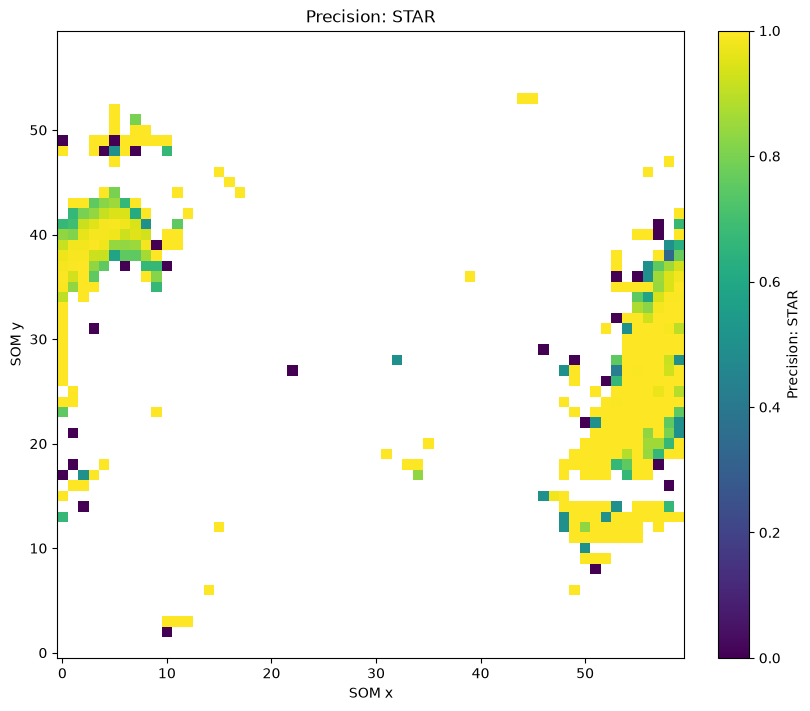

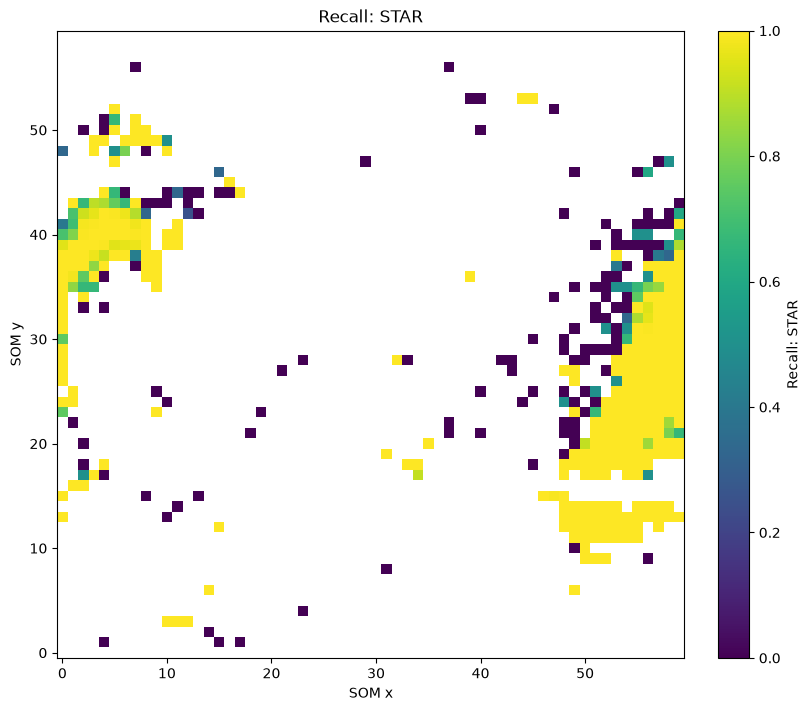

In [8]:
for class_name in classes:
    class_key = class_name.lower()
    plot_cell_map(cell_stats[f'true_fraction_{class_key}'],
                  f'True fraction: {class_name}', vmin=0, vmax=1)
    plot_cell_map(cell_stats[f'precision_{class_key}'],
                  f'Precision: {class_name}', vmin=0, vmax=1)
    plot_cell_map(cell_stats[f'recall_{class_key}'],
                  f'Recall: {class_name}', vmin=0, vmax=1)


CLASS_STAR    0.236631
J/Ks          0.117090
H/Ks          0.093650
u/g           0.066803
Name: importance, dtype: float32


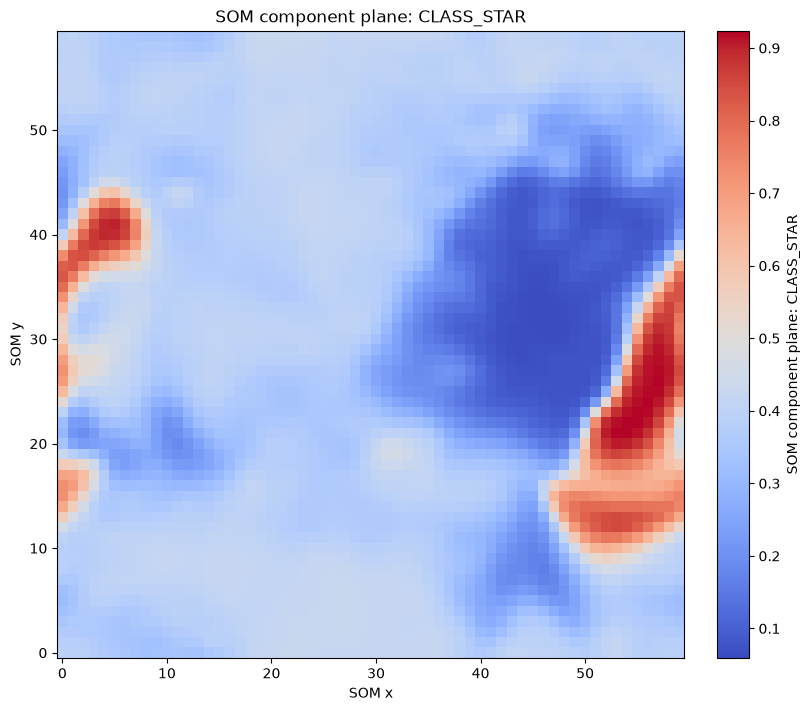

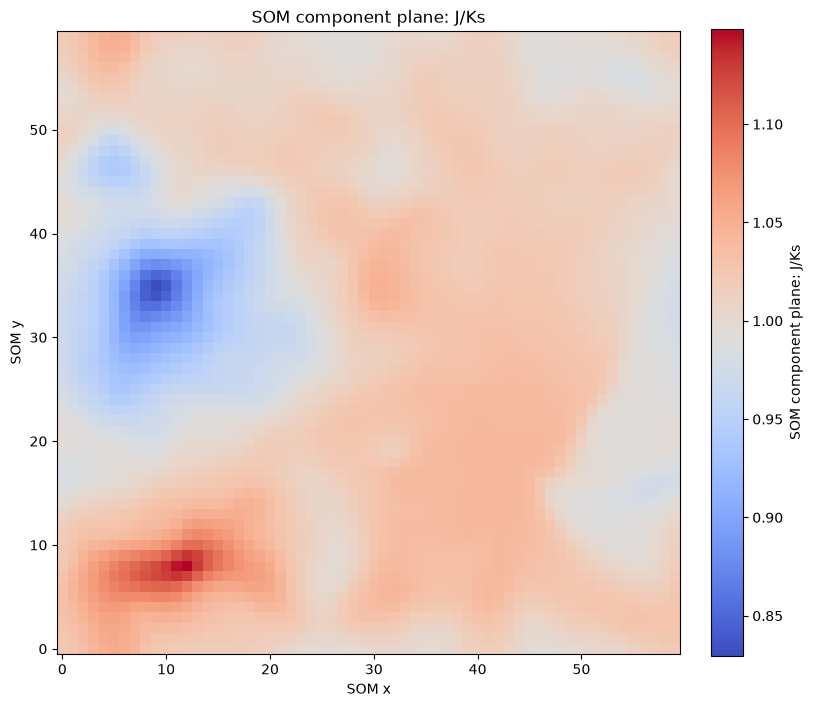

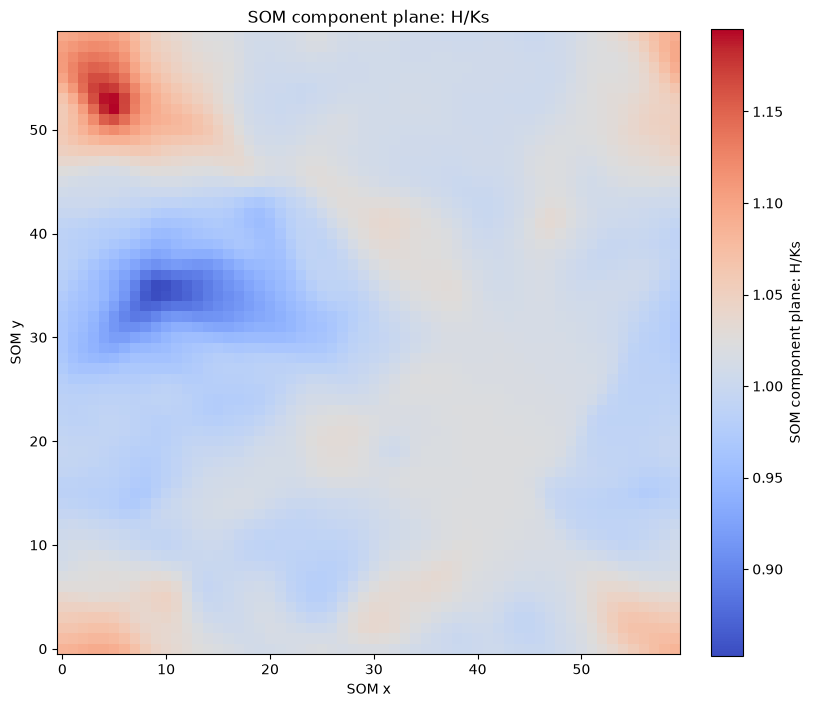

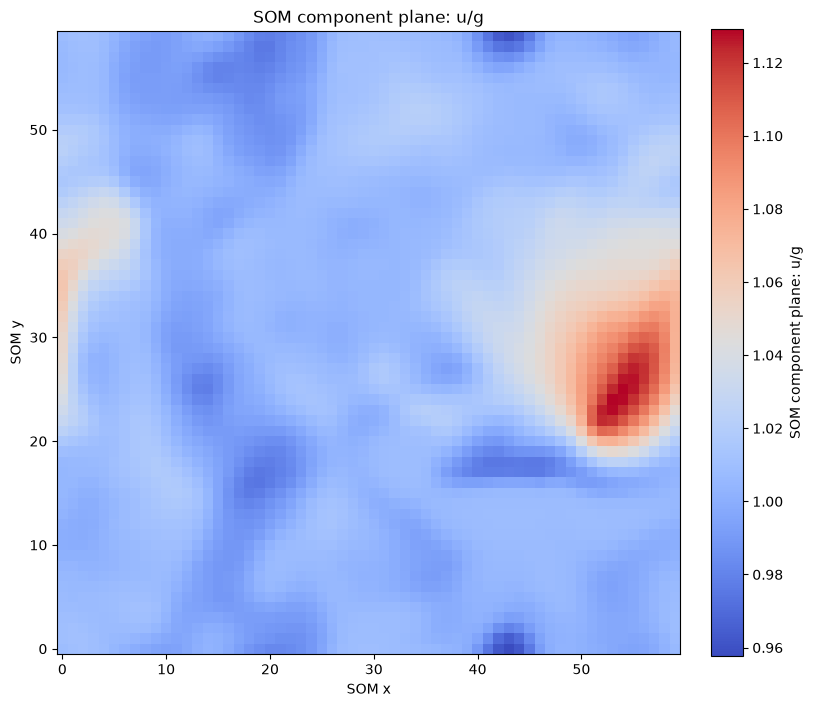

In [9]:
feature_importance = pd.Series(
    xgb_clf.model.feature_importances_, index=clf_features, name='importance'
).sort_values(ascending=False)
top_features = feature_importance.head(4).index.tolist()
print(feature_importance.head(4))
for feature_name in top_features:
    plot_som_component(feature_name)


## Raw-feature context

Raw r magnitude is not a SOM component because the saved SOM was trained without `MAG_GAAP_r`; this map is the per-cell test-set mean. If an S/N column is added to the catalog, set its name in `RAW_FEATURES`; otherwise that optional map is skipped.

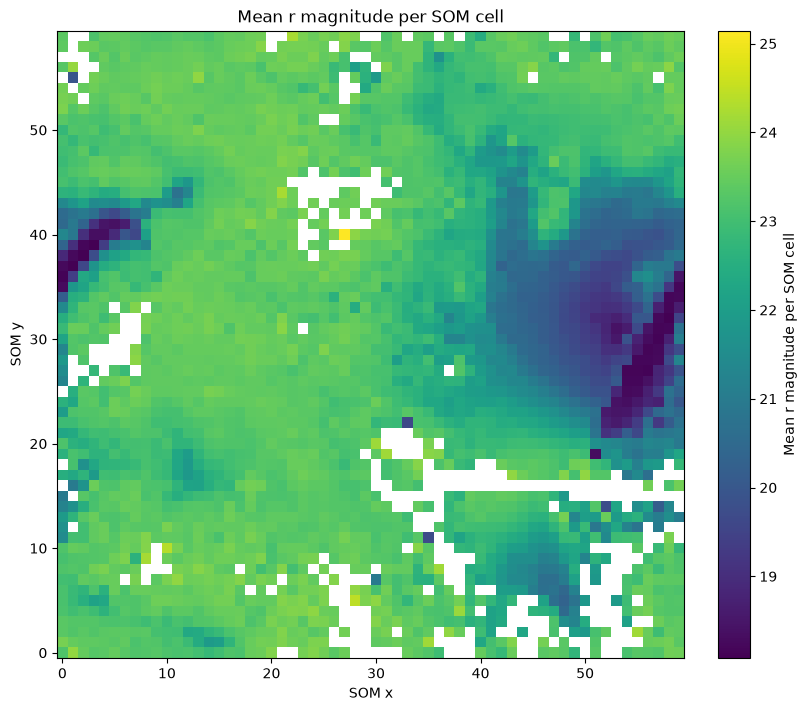

Skipping S/N: catalog column 'SNR_r' is not available.


In [10]:
RAW_FEATURES = {'r magnitude': 'MAG_GAAP_r', 'S/N': 'SNR_r'}
for label, column in RAW_FEATURES.items():
    if column not in raw_test:
        print(f'Skipping {label}: catalog column {column!r} is not available.')
        continue
    values = assignments.assign(raw_value=raw_test[column].to_numpy()).groupby('cell_id')['raw_value'].mean()
    plot_cell_map(values, f'Mean {label} per SOM cell', cmap='viridis')

In [11]:
xgb_clf.model.feature_importances_

array([0.00355673, 0.00546887, 0.00347384, 0.00228233, 0.00259928,
       0.00277959, 0.00574816, 0.00349089, 0.00643104, 0.00511963,
       0.00295198, 0.00248237, 0.00626878, 0.00613963, 0.0105936 ,
       0.0034949 , 0.00914294, 0.00269511, 0.00249613, 0.00455065,
       0.00932212, 0.01505888, 0.0033021 , 0.00501326, 0.00349652,
       0.0023991 , 0.00343605, 0.00463898, 0.00780439, 0.00267165,
       0.00260506, 0.00299439, 0.00286801, 0.00252835, 0.00252508,
       0.00654551, 0.00343575, 0.00371789, 0.00613385, 0.00470936,
       0.00523901, 0.00988226, 0.00690654, 0.06152543, 0.01960322,
       0.06680302, 0.03137453, 0.0026627 , 0.0027674 , 0.00308819,
       0.00306013, 0.00326535, 0.0036002 , 0.00779589, 0.00727534,
       0.00660041, 0.00299465, 0.00502349, 0.00506973, 0.00394539,
       0.0048601 , 0.0071953 , 0.00302845, 0.00393948, 0.00705737,
       0.00293481, 0.00490222, 0.00566708, 0.00775412, 0.00448197,
       0.00219149, 0.00226028, 0.00240831, 0.00234897, 0.00413

In [12]:
clf_features

['u-g',
 'u-r',
 'u-i1',
 'u-i2',
 'u-Z',
 'u-Y',
 'u-J',
 'u-H',
 'u-Ks',
 'g-r',
 'g-i1',
 'g-i2',
 'g-Z',
 'g-Y',
 'g-J',
 'g-H',
 'g-Ks',
 'r-i1',
 'r-i2',
 'r-Z',
 'r-Y',
 'r-J',
 'r-H',
 'r-Ks',
 'i1-i2',
 'i1-Z',
 'i1-Y',
 'i1-J',
 'i1-H',
 'i1-Ks',
 'i2-Z',
 'i2-Y',
 'i2-J',
 'i2-H',
 'i2-Ks',
 'Z-Y',
 'Z-J',
 'Z-H',
 'Z-Ks',
 'Y-J',
 'Y-H',
 'Y-Ks',
 'J-H',
 'J-Ks',
 'H-Ks',
 'u/g',
 'u/r',
 'u/i1',
 'u/i2',
 'u/Z',
 'u/Y',
 'u/J',
 'u/H',
 'u/Ks',
 'g/r',
 'g/i1',
 'g/i2',
 'g/Z',
 'g/Y',
 'g/J',
 'g/H',
 'g/Ks',
 'r/i1',
 'r/i2',
 'r/Z',
 'r/Y',
 'r/J',
 'r/H',
 'r/Ks',
 'i1/i2',
 'i1/Z',
 'i1/Y',
 'i1/J',
 'i1/H',
 'i1/Ks',
 'i2/Z',
 'i2/Y',
 'i2/J',
 'i2/H',
 'i2/Ks',
 'Z/Y',
 'Z/J',
 'Z/H',
 'Z/Ks',
 'Y/J',
 'Y/H',
 'Y/Ks',
 'J/H',
 'J/Ks',
 'H/Ks',
 'CLASS_STAR']